# Week 4 Capstone — Predicting Internship Selection Outcomes
**NextGenLearners | Jamsad Chowdhury**

This notebook follows the Week 4 capstone task guide, combining cleaning, exploratory review, feature preparation, model training, evaluation, interpretation, and a non-technical executive summary. Run all cells from top to bottom.

## Step 1 — Setup and dataset loading
The input is the cleaned Week 1 applicant dataset. Week 2 EDA and Week 3 SQL notebooks provide project context. This notebook deliberately excludes personal identifiers from model inputs.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

DATA_PATH = Path('data/applicants_cleaned.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('applicants_cleaned.csv')
df = pd.read_csv(DATA_PATH)
print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())
print('Missing values:')
print(df.isna().sum())
print('Status distribution:')
print(df['Status'].value_counts())

Dataset shape: (73, 7)
Columns: ['Applicant Name', 'Email', 'Phone', 'Domain Applied', 'University', 'Application Date', 'Status']
Missing values:
Applicant Name       0
Email                0
Phone                0
Domain Applied      13
University           0
Application Date    52
Status               0
dtype: int64
Status distribution:
Status
Under Review    34
Selected        23
Rejected        16
Name: count, dtype: int64


## Step 2 — Extend the dataset with four simulated features
**Required disclosure:** `num_skills_listed`, `has_portfolio`, `prior_hackathon_participation`, and `statement_quality_score` are artificially simulated for this learning exercise, **not collected from actual applications**. They must not be interpreted as evidence of real selection factors. A fixed random seed ensures reproducibility. The simulation is independent of the real selection labels; no predictive relationship is guaranteed.

In [9]:
np.random.seed(42)
df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))
df['has_portfolio'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.4, 0.6])
df['prior_hackathon_participation'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.3, 0.7])
df['statement_quality_score'] = np.random.randint(1, 11, size=len(df))
print(df[['num_skills_listed','has_portfolio','prior_hackathon_participation','statement_quality_score']].head())

   num_skills_listed has_portfolio prior_hackathon_participation  \
0                  7           Yes                            No   
1                  4           Yes                            No   
2                  5           Yes                            No   
3                  7            No                            No   
4                  3            No                           Yes   

   statement_quality_score  
0                       10  
1                        3  
2                        7  
3                       10  
4                        9  


## Step 3 — Prepare numeric features and the target
- Encode Yes/No as 1/0.
- Use only confirmed `Selected` and `Rejected` outcomes; `Under Review` has no final outcome and is excluded from training.
- Replace missing `Domain Applied` with the explicit category `Unknown` (rather than silently dropping applicants).
- One-hot encode `Domain Applied` with `drop_first=True` to avoid redundant dummy columns.
- Exclude names, emails, phones, university and application dates from the specified feature set. Identifiers are inappropriate model inputs; the other columns are outside the assigned feature set and/or have missing values.

In [10]:
df['has_portfolio'] = df['has_portfolio'].map({'Yes': 1, 'No': 0})
df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({'Yes': 1, 'No': 0})
df_model = df[df['Status'].isin(['Selected', 'Rejected'])].copy()
df_model['target'] = (df_model['Status'] == 'Selected').astype(int)
print('Confirmed outcome counts:')
print(df_model['Status'].value_counts())
print('Missing Domain Applied among confirmed outcomes:', df_model['Domain Applied'].isna().sum())
df_model['Domain Applied'] = df_model['Domain Applied'].fillna('Unknown')
df_model = pd.get_dummies(df_model, columns=['Domain Applied'], drop_first=True)
feature_columns = ['num_skills_listed','has_portfolio','prior_hackathon_participation','statement_quality_score'] + [col for col in df_model.columns if col.startswith('Domain Applied_')]
X = df_model[feature_columns].astype(float)
y = df_model['target']
assert X.isna().sum().sum() == 0
assert set(y.unique()) == {0, 1}
print('Feature columns:', feature_columns)
print('Model matrix:', X.shape)

Confirmed outcome counts:
Status
Selected    23
Rejected    16
Name: count, dtype: int64
Missing Domain Applied among confirmed outcomes: 7
Feature columns: ['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score', 'Domain Applied_Data Science', 'Domain Applied_Digital Marketing', 'Domain Applied_Graphic Design', 'Domain Applied_Unknown', 'Domain Applied_Web Development']
Model matrix: (39, 9)


## Step 4 — 80/20 train/test split
The held-out test set is not used to train the model. `random_state=42` keeps the split repeatable. With only 39 confirmed outcomes, the test set will be very small; results should be interpreted cautiously. Stratification preserves both class proportions where possible (an additional safeguard beyond the example code in the task guide).

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('Train class counts:', y_train.value_counts().to_dict())
print('Test class counts:', y_test.value_counts().to_dict())

Training rows: 31
Testing rows: 8
Train class counts: {1: 18, 0: 13}
Test class counts: {1: 5, 0: 3}


## Step 5 — Train one classification model
We select **Logistic Regression** as the single required model because it is a standard, interpretable approach for a binary Selected/Not Selected outcome. `.fit()` learns from training inputs and labels; `.predict()` assigns labels to unseen test rows. With a small dataset, model complexity is intentionally limited.

In [12]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Predicted labels:', y_pred.tolist())

Predicted labels: [1, 1, 0, 0, 0, 1, 0, 1]


## Step 6 — Evaluate the model honestly
**Accuracy:** fraction of all held-out predictions that are correct. **Precision:** among applicants predicted Selected, the fraction actually Selected. **Recall:** among truly Selected applicants, the fraction correctly identified. A confusion matrix shows true negatives, false positives, false negatives, and true positives. Accuracy alone can be misleading, especially with imbalanced outcomes.

Accuracy: 37.50%
Precision: 50.00%
Recall: 40.00%
Confusion matrix [[TN, FP], [FN, TP]]:
[[1 2]
 [3 2]]
Of 8 test applicants, 3 were correctly classified; 2 were incorrectly predicted Selected, and 3 actually Selected applicants were missed.


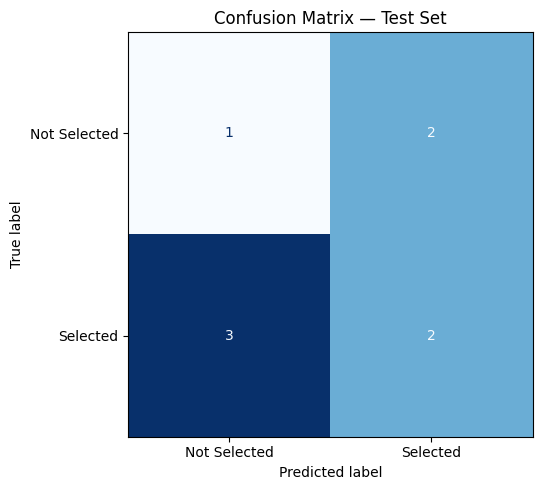

In [13]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print(f'Accuracy: {accuracy:.2%}')
print(f'Precision: {precision:.2%}')
print(f'Recall: {recall:.2%}')
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f'Of {len(y_test)} test applicants, {tn + tp} were correctly classified; {fp} were incorrectly predicted Selected, and {fn} actually Selected applicants were missed.')
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Selected', 'Selected']).plot(cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Confusion Matrix — Test Set')
fig.tight_layout()
Path('outputs').mkdir(exist_ok=True)
fig.savefig('outputs/confusion_matrix.png', dpi=160)
plt.show()

### Required limitations and responsible interpretation
1. **Small sample:** only 39 applicants have confirmed outcomes; the held-out test set has only about eight cases. A few different predictions could substantially change the percentages.
2. **Simulated data:** four model features were generated randomly rather than observed historically. Consequently, performance and feature associations are illustrative, not validated recruitment findings.
3. **Potential bias:** historical selection labels can encode subjective or unfair patterns, which models may reproduce or amplify.
4. **Decision support only:** this exercise is not suitable for operational screening or automatic selection; qualified human review and validation on larger real data are essential.
5. **No causal claims:** a positive model association does not prove a feature causes selection.

## Step 7 — Interpret which features mattered
Logistic regression coefficients describe the direction of model association holding other encoded inputs constant. Positive values increase predicted selection log-odds; negative values decrease them. **Raw coefficient sizes are not directly comparable across differently scaled features**, and domain dummy coefficients are relative to the omitted reference category. The table and plot below show what this particular fitted model learned, not real selection criteria.

                         Feature  Coefficient
   Domain Applied_Graphic Design     0.489419
               num_skills_listed     0.476233
Domain Applied_Digital Marketing     0.405686
     Domain Applied_Data Science     0.384980
  Domain Applied_Web Development     0.368382
         statement_quality_score    -0.018912
   prior_hackathon_participation    -0.345046
          Domain Applied_Unknown    -0.523953
                   has_portfolio    -0.831810


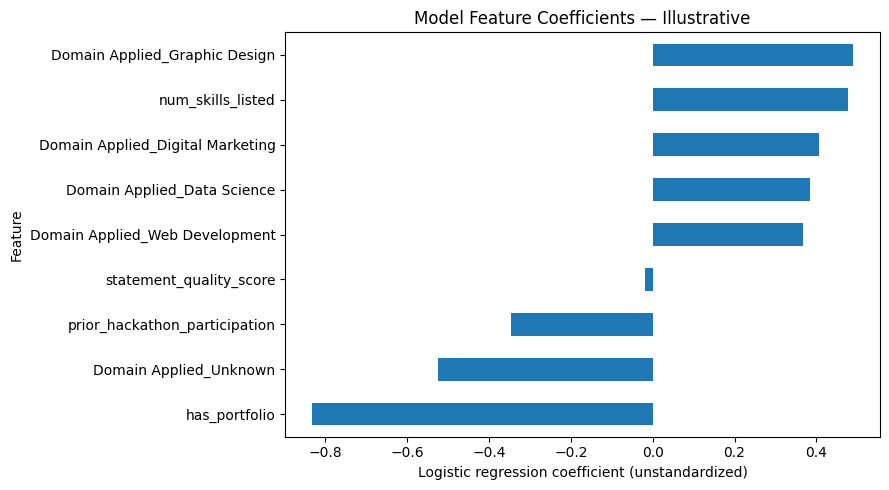

Largest positive coefficient: Domain Applied_Graphic Design
Largest negative coefficient: has_portfolio


In [14]:
coefficients = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_[0]}).sort_values('Coefficient', ascending=False)
print(coefficients.to_string(index=False))
coefficients.to_csv('outputs/feature_coefficients.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 5))
coefficients.sort_values('Coefficient').plot.barh(x='Feature', y='Coefficient', legend=False, ax=ax)
ax.set_xlabel('Logistic regression coefficient (unstandardized)')
ax.set_title('Model Feature Coefficients — Illustrative')
fig.tight_layout()
fig.savefig('outputs/feature_coefficients.png', dpi=160)
plt.show()
print('Largest positive coefficient:', coefficients.iloc[0]['Feature'])
print('Largest negative coefficient:', coefficients.iloc[-1]['Feature'])

### Interpretation of observed results
The coefficient table and chart identify the inputs with positive and negative associations **in this particular small, partly simulated sample**. Any apparent ranking is exploratory. In particular, the four random features were not measured from applicants and should not be used to infer what NextGenLearners actually values. Re-run the notebook to see the exact coefficients.

## Step 8 — Executive Summary

**What we did:** We used the cleaned internship application dataset to explore whether a simple model could predict applicants' final selection outcomes. Of 73 applications, 39 had a confirmed Selected or Rejected result; 34 were still Under Review and were not used to train the model.

**What we found:** On a held-out group of **8 applicants**, the model correctly classified **37.5%**. Among applicants it predicted would be selected, **50.0%** were actually selected; it identified **40.0%** of those who were selected. The test group is very small, so these figures should not be treated as reliable forecasts of future performance. The analysis also highlights which inputs the model used, but those patterns do not establish actual reasons for selection.

**Important caveats:** Four input fields—skills listed, portfolio availability, hackathon participation and statement quality—were **simulated rather than taken from real application records**. Historical decisions may also reflect bias. This model is a learning demonstration, not a reliable hiring tool; any real deployment would require larger datasets, genuine consistently collected inputs, fairness checks and human oversight.

**Recommendation:** Before considering any operational prediction tool, collect the four application fields consistently in future applications and validate whether they provide useful and fair signals on a substantially larger set of confirmed real outcomes.

## Step 9 — README and project documentation
The companion `README.md` describes the objective, dataset, method, actual results, execution instructions, and the walkthrough-video link placeholder. Replace that placeholder after recording and uploading your video.

## Step 10 — Recorded Video Link :
https://drive.google.com/file/d/16JEkWrE47tfKAS1gBDgZBkRt3ADPvDk9/view?usp=sharing.

## Step 11 — Final submission checklist
- [x] Four simulated features, reproducible seed, explicit disclosure
- [x] Binary encoding, confirmed outcome target, domain one-hot encoding
- [x] 80/20 split and one trained model
- [x] Accuracy, precision, recall, confusion matrix and explanations
- [x] Limitations, possible bias and human-review framing
- [x] Coefficients and interpretation
- [x] Non-technical executive summary with recommendation
- [x] README and reproducible notebook
- [ ] Push repository to your own GitHub account
- [ ] Record/upload walkthrough video and replace README video link